In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("steel_plates_faults.csv")

# 확인할 컬럼
cols = [
    "X_Minimum", "X_Maximum",
    "Y_Minimum", "Y_Maximum",
    "Pixels_Areas",
    "X_Perimeter", "Y_Perimeter",
    "Sum_of_Luminosity",
    "Minimum_of_Luminosity", "Maximum_of_Luminosity",
    "Length_of_Conveyer",
    "TypeOfSteel_A300", "TypeOfSteel_A400",
    "Steel_Plate_Thickness",
    "Edges_Index",
    "Empty_Index", "Square_Index",
    "Outside_X_Index",
    "Edges_X_Index", "Edges_Y_Index",
    "Outside_Global_Index",
    "LogOfAreas",
    "Log_X_Index", "Log_Y_Index",
    "Orientation_Index",
    "Luminosity_Index",
    "SigmoidOfAreas"
]

cols = [col for col in cols if col in df.columns]

# 결함 클래스 생성
fault_cols = [
    "Pastry", "Z_Scratch", "K_Scatch",
    "Stains", "Dirtiness", "Bumps", "Other_Faults"
]

if "Fault_Type" not in df.columns:
    existing_fault_cols = [
        col for col in fault_cols if col in df.columns
    ]
    df["Fault_Type"] = df[existing_fault_cols].idxmax(axis=1)

# 1) 컬럼별 기본 정보
summary = pd.DataFrame({
    "자료형": df[cols].dtypes.astype(str),
    "결측치": df[cols].isna().sum(),
    "고유값_개수": df[cols].nunique(),
    "최솟값": df[cols].min(),
    "최댓값": df[cols].max(),
    "평균": df[cols].mean(),
    "중앙값": df[cols].median(),
    "25%": df[cols].quantile(0.25),
    "75%": df[cols].quantile(0.75)
}).round(3)

display(summary)

,자료형,결측치,고유값_개수,최솟값,최댓값,평균,중앙값,25%,75%
X_Minimum,int64,0,962,0.000,1.705000e+03,571.136,435.000,51.000,1053.000
X_Maximum,int64,0,994,4.000,1.713000e+03,617.964,467.000,192.000,1072.000
Y_Minimum,int64,0,1939,6712.000,1.298766e+07,1650684.868,1204128.000,471253.000,2183073.000
Y_Maximum,int64,0,1940,6724.000,1.298769e+07,1650738.705,1204136.000,471281.000,2183084.000
Pixels_Areas,int64,0,920,2.000,1.526550e+05,1893.878,174.000,84.000,822.000
X_Perimeter,int64,0,399,2.000,1.044900e+04,111.855,26.000,15.000,84.000
Y_Perimeter,int64,0,317,1.000,1.815200e+04,82.966,25.000,13.000,83.000
Sum_of_Luminosity,int64,0,1909,250.000,1.159141e+07,206312.148,19202.000,9522.000,83011.000
Minimum_of_Luminosity,int64,0,161,0.000,2.030000e+02,84.549,90.000,63.000,106.000
Maximum_of_Luminosity,int64,0,100,37.000,2.530000e+02,130.194,127.000,124.000,140.000


In [2]:
for col in cols:
    unique_values = sorted(df[col].dropna().unique())

    print(f"\n[{col}]")
    print(f"고유값 개수: {len(unique_values)}")

    if len(unique_values) <= 30:
        print("고유값:", unique_values)
    else:
        print("앞부분:", unique_values[:10])
        print("뒷부분:", unique_values[-10:])


[X_Minimum]
고유값 개수: 962
앞부분: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
뒷부분: [np.int64(1675), np.int64(1677), np.int64(1678), np.int64(1680), np.int64(1682), np.int64(1683), np.int64(1685), np.int64(1687), np.int64(1688), np.int64(1705)]

[X_Maximum]
고유값 개수: 994
앞부분: [np.int64(4), np.int64(5), np.int64(6), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]
뒷부분: [np.int64(1686), np.int64(1687), np.int64(1688), np.int64(1689), np.int64(1690), np.int64(1692), np.int64(1694), np.int64(1696), np.int64(1712), np.int64(1713)]

[Y_Minimum]
고유값 개수: 1939
앞부분: [np.int64(6712), np.int64(7003), np.int64(7430), np.int64(7851), np.int64(9007), np.int64(9228), np.int64(12799), np.int64(13302), np.int64(14524), np.int64(15184)]
뒷부분: [np.int64(11499942), np.int64(11569824), np.int64(11741476), np.int64(12416454), np.int64(12438460), np.int64(12577343), np.int64(12725281),

In [3]:
# 클래스별 수치 요약
for col in cols:
    print(f"\n===== {col} =====")

    result = df.groupby("Fault_Type")[col].agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).round(3)

    display(result)


===== X_Minimum =====


,count,mean,median,std,min,max
Fault_Type,,,,,,
Bumps,402,796.532,856.5,456.248,6,1680
Dirtiness,55,887.927,625.0,422.442,1,1444
K_Scatch,391,136.593,41.0,265.861,0,1614
Other_Faults,673,688.893,655.0,513.595,0,1705
Pastry,158,807.133,823.0,600.502,0,1688
Stains,72,766.708,754.0,323.946,297,1291
Z_Scratch,190,209.316,106.0,312.318,0,1341



===== X_Maximum =====


,count,mean,median,std,min,max
Fault_Type,,,,,,
Bumps,402,814.306,878.0,454.993,15,1689
Dirtiness,55,899.164,636.0,422.761,16,1466
K_Scatch,391,285.061,212.0,236.496,9,1638
Other_Faults,673,717.517,727.0,512.807,4,1713
Pastry,158,818.203,836.0,600.321,10,1696
Stains,72,773.778,760.5,323.553,302,1295
Z_Scratch,190,228.042,123.0,311.853,6,1347



===== Y_Minimum =====


...

,count,mean,median,std,min,max
Fault_Type,,,,,,
Bumps,402,0.097,0.100,0.349,-0.932,0.811
Dirtiness,55,0.595,0.800,0.514,-0.852,0.937
K_Scatch,391,-0.300,-0.515,0.365,-0.841,0.992
Other_Faults,673,0.113,0.182,0.530,-0.991,0.947
Pastry,158,0.637,0.667,0.235,-0.538,0.961
Stains,72,-0.265,-0.268,0.233,-0.720,0.333
Z_Scratch,190,0.262,0.351,0.424,-0.762,0.939



===== Luminosity_Index =====


,count,mean,median,std,min,max
Fault_Type,,,,,,
Bumps,402,-0.150,-0.143,0.093,-0.597,0.121
Dirtiness,55,-0.092,-0.088,0.072,-0.273,0.140
K_Scatch,391,-0.102,-0.156,0.172,-0.999,0.592
Other_Faults,673,-0.123,-0.119,0.167,-0.885,0.642
Pastry,158,-0.185,-0.179,0.118,-0.582,0.279
Stains,72,-0.014,-0.003,0.046,-0.207,0.062
Z_Scratch,190,-0.191,-0.165,0.140,-0.610,0.016



===== SigmoidOfAreas =====


,count,mean,median,std,min,max
Fault_Type,,,,,,
Bumps,402,0.439,0.310,0.271,0.145,1.000
Dirtiness,55,0.585,0.406,0.348,0.185,1.000
K_Scatch,391,0.916,1.000,0.233,0.119,1.000
Other_Faults,673,0.538,0.417,0.314,0.132,1.000
Pastry,158,0.566,0.511,0.296,0.150,1.000
Stains,72,0.149,0.138,0.040,0.124,0.398
Z_Scratch,190,0.565,0.457,0.320,0.177,1.000


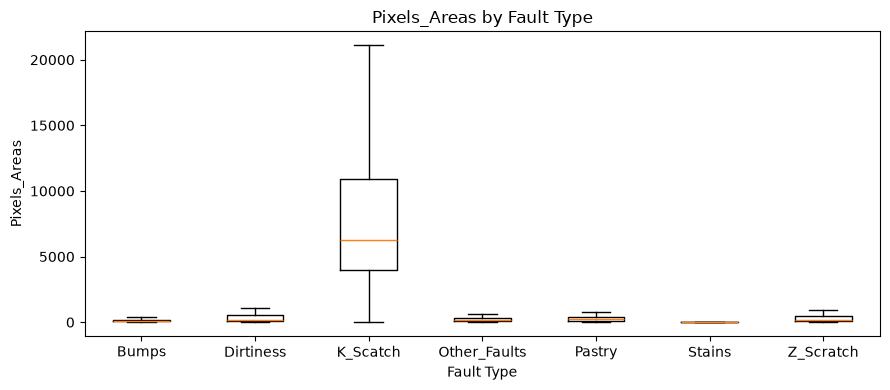

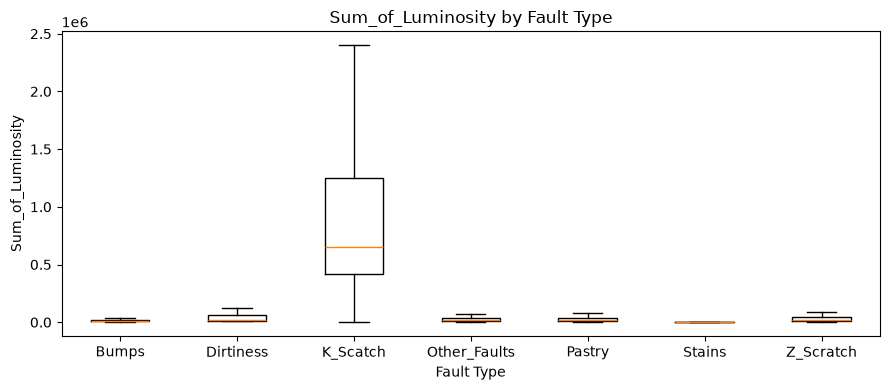

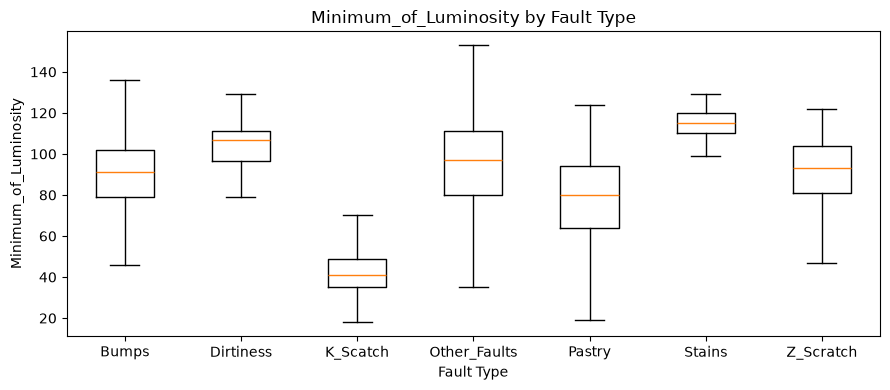

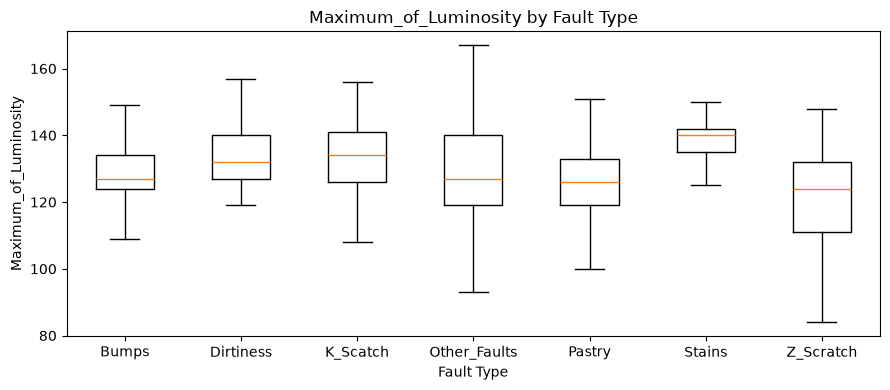

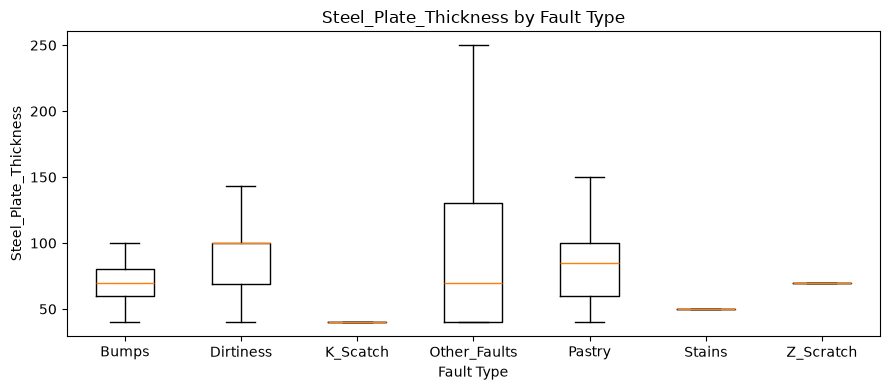

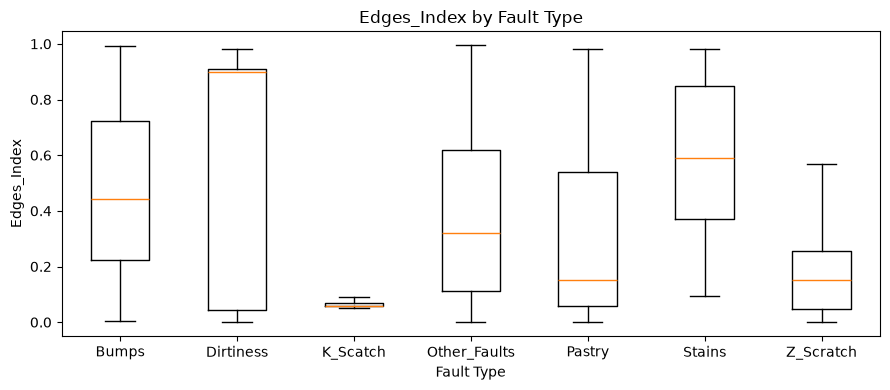

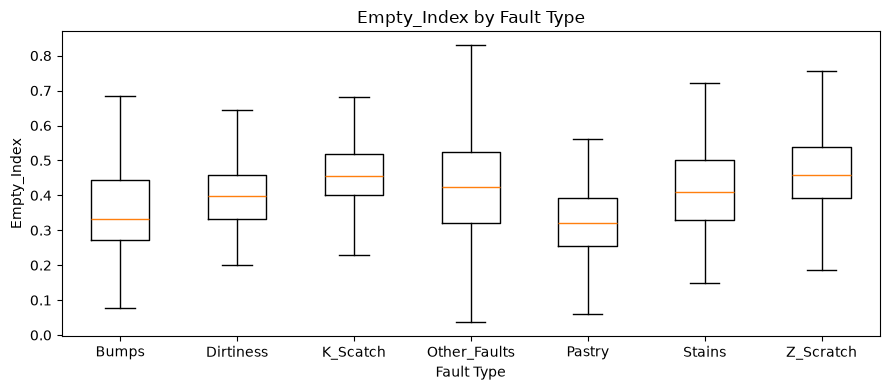

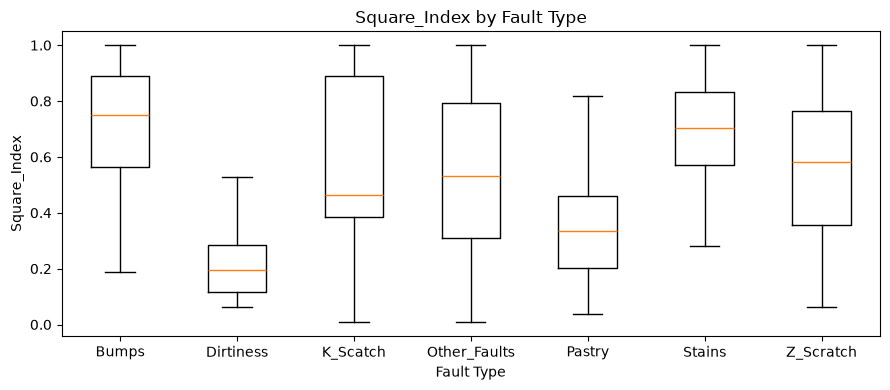

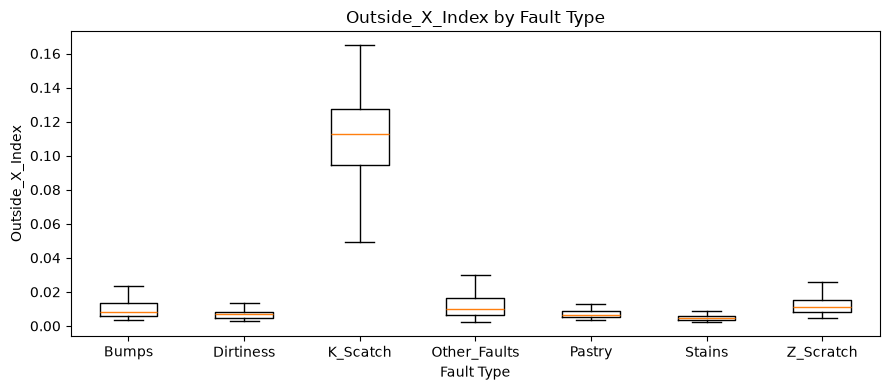

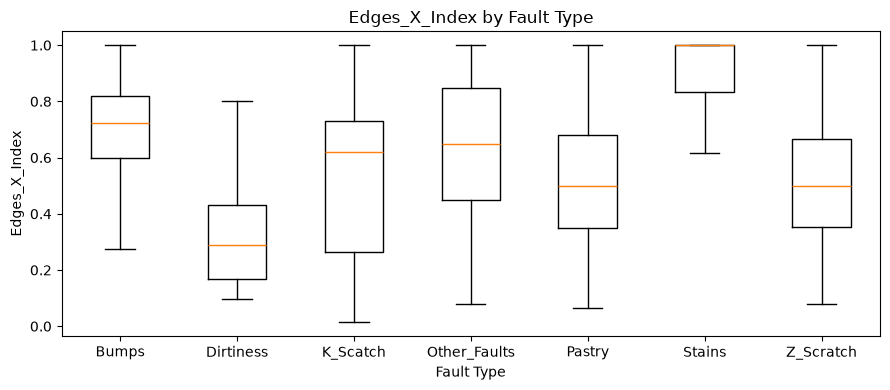

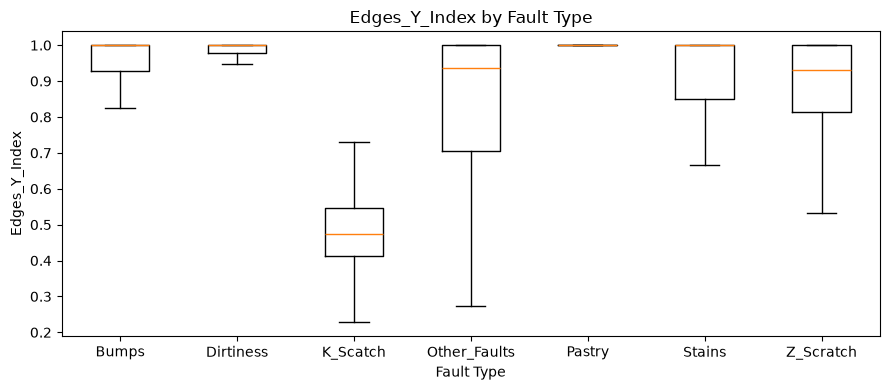

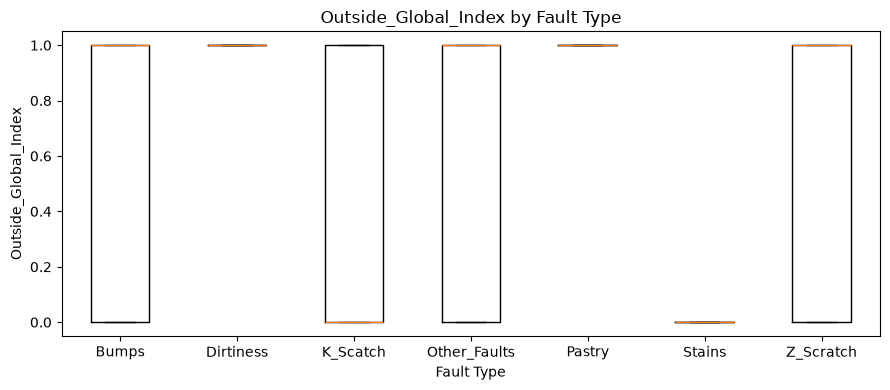

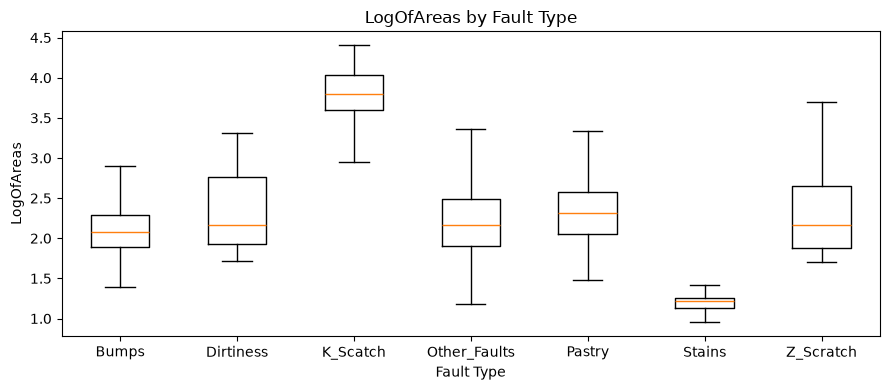

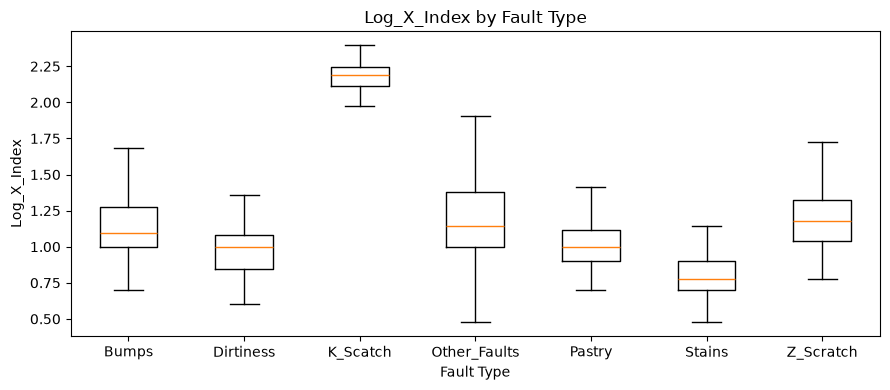

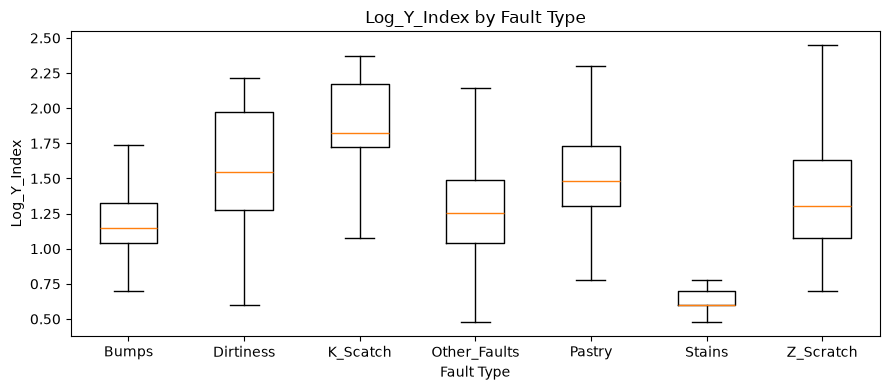

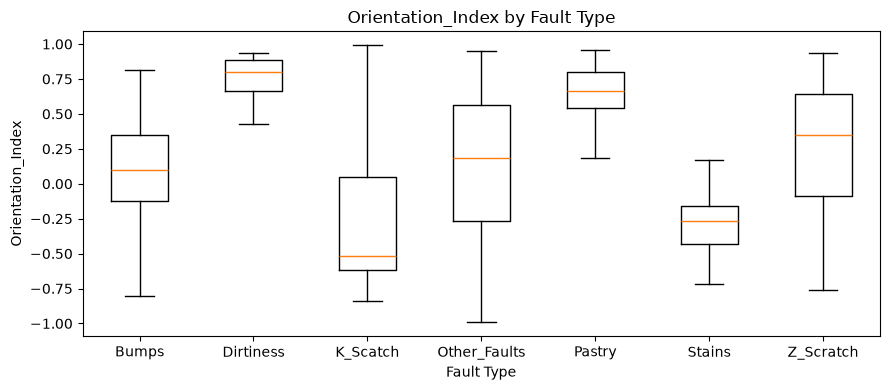

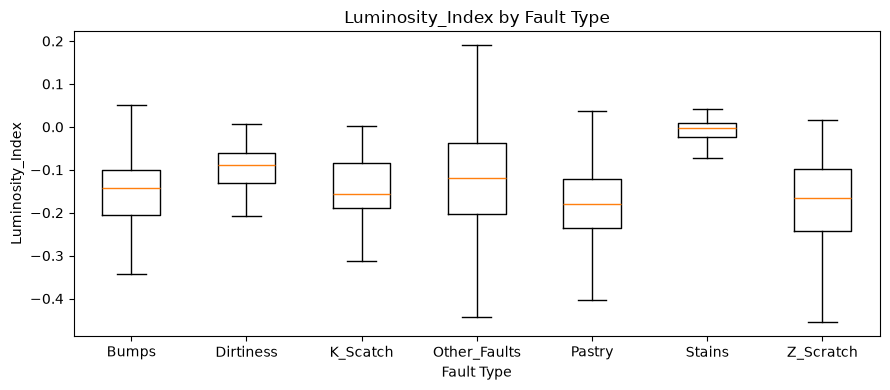

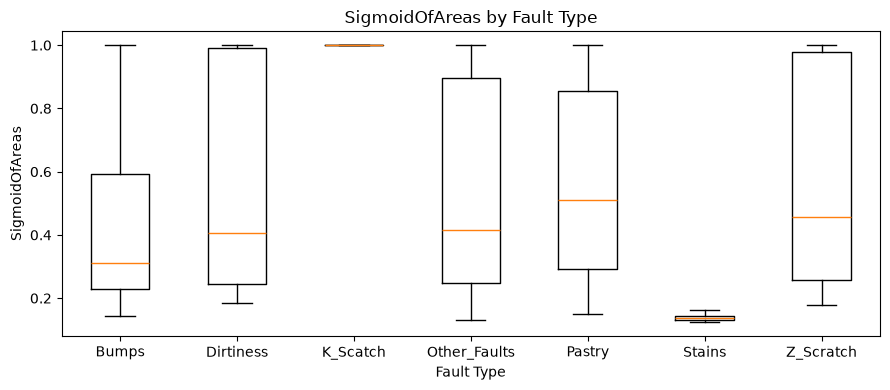

In [4]:
import matplotlib.pyplot as plt

# 한 번에 확인할 변수 목록
plot_cols = [
    "Pixels_Areas",
    "Sum_of_Luminosity",
    "Minimum_of_Luminosity",
    "Maximum_of_Luminosity",
    "Steel_Plate_Thickness",
    "Edges_Index",
    "Empty_Index",
    "Square_Index",
    "Outside_X_Index",
    "Edges_X_Index",
    "Edges_Y_Index",
    "Outside_Global_Index",
    "LogOfAreas",
    "Log_X_Index",
    "Log_Y_Index",
    "Orientation_Index",
    "Luminosity_Index",
    "SigmoidOfAreas"
]

plot_cols = [col for col in plot_cols if col in df.columns]

for col in plot_cols:
    fig, ax = plt.subplots(figsize=(9, 4))

    groups = [
        df.loc[df["Fault_Type"] == fault, col].dropna()
        for fault in sorted(df["Fault_Type"].dropna().unique())
    ]

    ax.boxplot(
        groups,
        tick_labels=sorted(df["Fault_Type"].dropna().unique()),
        showfliers=False
    )

    ax.set_title(f"{col} by Fault Type")
    ax.set_xlabel("Fault Type")
    ax.set_ylabel(col)
    plt.tight_layout()
    plt.show()

In [5]:
# 예시: 두께 구간
df["Thickness_Group"] = pd.cut(
    df["Steel_Plate_Thickness"],
    bins=[-np.inf, 40, 60, 80, 150, 300, np.inf],
    labels=["40 이하", "40~60", "60~80", "80~150", "150~300", "300 초과"]
)

# 클래스 내부 비율(%)
thickness_dist = pd.crosstab(
    df["Fault_Type"],
    df["Thickness_Group"],
    normalize="index"
).mul(100).round(1)

display(thickness_dist)

# 각 구간에 어떤 클래스가 많이 포함되는지도 확인
thickness_class_dist = pd.crosstab(
    df["Thickness_Group"],
    df["Fault_Type"],
    normalize="index"
).mul(100).round(1)

display(thickness_class_dist)

Thickness_Group,40 이하,40~60,60~80,80~150,150~300
Fault_Type,,,,,
Bumps,19.4,18.4,43.0,12.2,7.0
Dirtiness,21.8,1.8,14.5,61.8,0.0
K_Scatch,99.0,0.8,0.3,0.0,0.0
Other_Faults,28.4,5.2,28.2,17.1,21.1
Pastry,21.5,11.4,17.1,39.9,10.1
Stains,0.0,98.6,0.0,1.4,0.0
Z_Scratch,4.2,0.0,89.5,1.1,5.3


Fault_Type,Bumps,Dirtiness,K_Scatch,Other_Faults,Pastry,Stains,Z_Scratch
Thickness_Group,,,,,,,
40 이하,11.0,1.7,54.5,26.9,4.8,0.0,1.1
40~60,36.6,0.5,1.5,17.3,8.9,35.1,0.0
60~80,30.4,1.4,0.2,33.4,4.7,0.0,29.9
80~150,18.6,12.9,0.0,43.6,23.9,0.4,0.8
150~300,14.3,0.0,0.0,72.4,8.2,0.0,5.1
